# RiMEA 03: Walking Speed on Downstairs

A single agent traverses a 10 m stair section in the downward direction. RiMEA verifies that the model reproduces the assigned stair speed and notes that *"the user defines a speed factor"* for stairs. We model the stair as a planar 2 m corridor (extended to 30 m with 10 m run-up + 10 m buffer) carrying a **`speed_factor = 0.65` zone over the measured segment (x = 10–20)**, so the agent walks the run-up at the 1.0 m/s free speed and the stair at **0.65 m/s**, covering the 10 m incline in **~15 s**. The same assigned speed applies up or down.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 19:34 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

## Load and run the scenario

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Rimea-03-downstairs.zip"
scenario = load_scenario(str(SCENARIO_ZIP))
print(scenario.summary())
result = run_scenario(scenario, seed=42)

Scenario: scenario_files/Rimea-03-downstairs.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      60s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         1
  Journeys:      0
  Agents:        ~1
    jps-distributions_0: 1 agents


## Measure walking speed across the 10 m stair segment

The segment x = 10–20 sits inside the `speed_factor = 0.65` zone, so the expected stair speed is 0.65 m/s and the expected transit time is ~15 s.

In [6]:
df = result.trajectory_dataframe().sort_values(['id', 'frame'])
MEAS_START_X = 10.0
MEAS_END_X = 20.0
DIRECTION = 'right'
rows = []
for agent_id, sub in df.groupby('id'):
    if DIRECTION == 'right':
        a = sub[sub.x >= MEAS_START_X]; b = sub[sub.x >= MEAS_END_X]
    else:
        a = sub[sub.x <= MEAS_START_X]; b = sub[sub.x <= MEAS_END_X]
    if a.empty or b.empty:
        continue
    t_in = a.iloc[0].frame / result.frame_rate
    t_out = b.iloc[0].frame / result.frame_rate
    rows.append({'id': int(agent_id), 't_in_s': t_in, 't_out_s': t_out, 'transit_s': t_out - t_in})
transit = pd.DataFrame(rows)
transit['speed_m_s'] = abs(MEAS_END_X - MEAS_START_X) / transit['transit_s']
transit

,id,t_in_s,t_out_s,transit_s,speed_m_s
0,1,8.8,24.2,15.4,0.649351


## Scenario figure

Corridor geometry from the loaded scenario with the measurement segment.

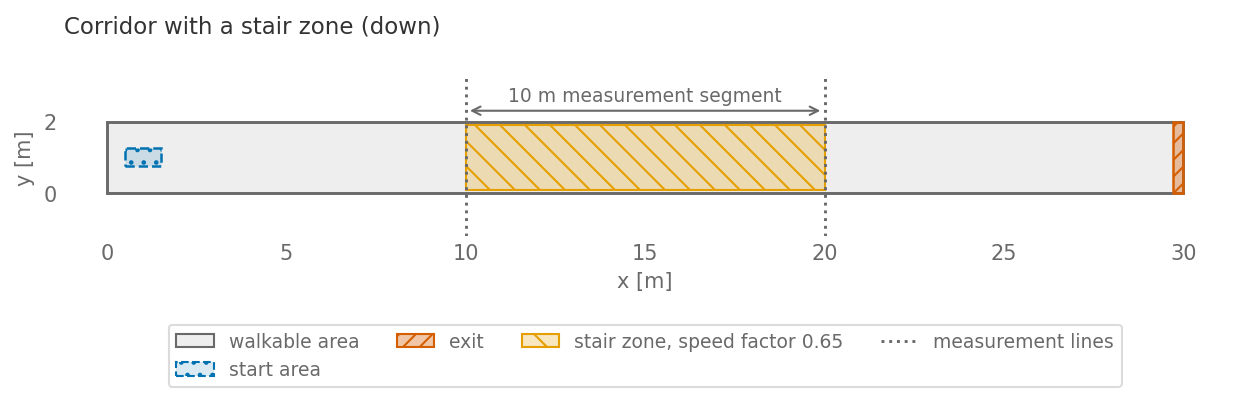

In [7]:
# Scenario geometry from the loaded ZIP, with the measurement segment.
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(10, 2.6))
    handles = vv_draw_scenario(ax, scenario)
    for z in scenario.zones.values():
        ax.add_patch(MplPolygon(z["coordinates"], closed=True, facecolor=to_rgba(VV_ORANGE, 0.25),
                                edgecolor=VV_ORANGE, hatch="\\\\", linewidth=1.0, zorder=2))
    handles.append(Patch(facecolor=to_rgba(VV_ORANGE, 0.25), edgecolor=VV_ORANGE, hatch="\\\\",
                         label="stair zone, speed factor 0.65"))
    for x in (MEAS_START_X, MEAS_END_X):
        ax.axvline(x, color="dimgrey", ls=":", lw=1.4, zorder=4)
    handles.append(Line2D([], [], color="dimgrey", ls=":", lw=1.4, label="measurement lines"))
    ymin, ymax = scenario.walkable_polygon.bounds[1], scenario.walkable_polygon.bounds[3]
    ax.set_yticks([ymin, ymax])
    ax.annotate("", xy=(MEAS_END_X, ymax + 0.3), xytext=(MEAS_START_X, ymax + 0.3),
                arrowprops={"arrowstyle": "<->", "color": "dimgrey"}, annotation_clip=False)
    ax.text((MEAS_START_X + MEAS_END_X) / 2, ymax + 0.45,
            f"{abs(MEAS_END_X - MEAS_START_X):g} m measurement segment", ha="center", va="bottom",
            color="dimgrey", fontsize=9)
    ax.set_title("Corridor with a stair zone (down)", loc="left", pad=22)
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.5), ncol=4)
    plt.show()

## Plot trajectory x vs t

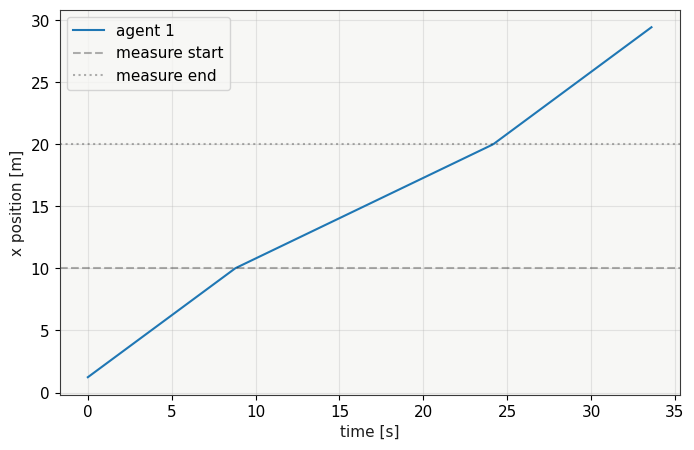

In [8]:
fig, ax = plt.subplots()
for agent_id, sub in df.groupby('id'):
    ax.plot(sub.frame / result.frame_rate, sub.x, label=f'agent {agent_id}')
ax.axhline(MEAS_START_X, color='k', ls='--', alpha=0.3, label='measure start')
ax.axhline(MEAS_END_X, color='k', ls=':', alpha=0.3, label='measure end')
ax.set_xlabel('time [s]'); ax.set_ylabel('x position [m]'); ax.legend()
plt.show()

## Result figure

Mean speed over the measurement segment against the accepted band of the acceptance check.

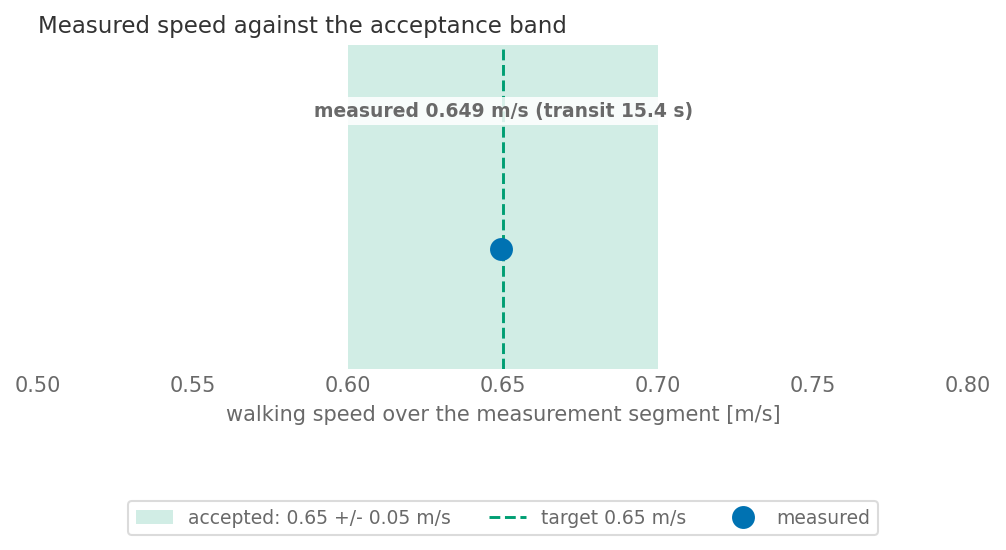

In [9]:
# Mean speed over the measurement segment against the accepted band.
TARGET, TOL = 0.65, 0.05  # same values as the acceptance cell
observed = transit["speed_m_s"]
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(8, 2.8))
    ax.axvspan(TARGET - TOL, TARGET + TOL, facecolor=to_rgba(VV_GREEN, 0.18), edgecolor=VV_GREEN,
               lw=0, label=f"accepted: {TARGET:g} +/- {TOL:g} m/s")
    ax.axvline(TARGET, color=VV_GREEN, ls="--", lw=1.4, label=f"target {TARGET:g} m/s")
    ax.plot(observed, np.zeros(len(observed)), "o", color=VV_BLUE, ms=10, zorder=4, label="measured")
    lo = min(TARGET - 3 * TOL, observed.min() - TOL)
    hi = max(TARGET + 3 * TOL, observed.max() + TOL)
    ax.set_xlim(lo, hi)
    ax.set_ylim(-1, 1.7)
    ax.set_yticks([])
    ax.set_xlabel("walking speed over the measurement segment [m/s]")
    ax.set_title("Measured speed against the acceptance band", loc="left")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.38), ncol=3)
    ax.text(0.5, 0.78, f"measured {observed.mean():.3f} m/s (transit {transit['transit_s'].mean():.1f} s)",
            transform=ax.transAxes, ha="center", color="dimgrey", fontweight="semibold", fontsize=9,
            bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none", "pad": 2})
    ax.grid(False)
    plt.show()

## Acceptance

In [10]:
TARGET = 0.65  # 1.0 m/s free speed x speed_factor 0.65
EXPECTED_TRANSIT_S = abs(MEAS_END_X - MEAS_START_X) / TARGET
TOL = 0.05
observed = transit['speed_m_s'].mean()
print(f'observed mean stair speed = {observed:.3f} m/s; target = {TARGET} m/s; '
      f'transit = {transit["transit_s"].mean():.2f} s; expected = {EXPECTED_TRANSIT_S:.2f} s')
assert abs(observed - TARGET) <= TOL, (observed, TARGET)
result.cleanup()

observed mean stair speed = 0.649 m/s; target = 0.65 m/s; transit = 15.40 s; expected = 15.38 s


1